# Simulasi Skenario Bahaya Luapan Kali Jagir dan Evakuasi Interaktif
**Kawasan Pintu Air Jagir, Wonokromo, Surabaya**
*Mata Kuliah: Grafika Komputer & GIS — Informatics Universitas Ciputra*
*Penanggung Jawab Data & CRS: ORANG 1 (Data Engineer & Lead Repository Integrator)*

---
### Ringkasan Parameter Kajian Spasial:
- **Area Studi Inti (EPSG:4326):** $112.728^{\circ} - 112.760^{\circ}$ BT, $-7.312^{\circ} - -7.292^{\circ}$ LS ($\approx 7.8\text{ km}^2$).
- **Sistem Proyeksi Analisis:** `EPSG:32749` (WGS 84 / UTM Zone 49S, satuan meter).
- **Aturan Ketat CRS:** Seluruh kalkulasi spasial (`.buffer()`, `.area`, `.distance()`) wajib dilakukan pada koordinat terproyeksi metrik (`EPSG:32749`).


## 1. Setup Lingkungan & Import Modul Spasial


In [1]:
from IPython.display import display
import os
import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from shapely.geometry import box, Point

# Import modul data layer buatan Orang 1
import src.data_layers as dl

print("Modul src.data_layers berhasil diimpor!")
print(f"CRS Acuan Analisis: {dl.CRS_METER}")


Modul src.data_layers berhasil diimpor!
CRS Acuan Analisis: EPSG:32749


## 2. Memuat Seluruh Layer Spasial (Orang 1)
Data spasial dimuat secara offline dari direktori `data/`, ditransformasikan ke `EPSG:32749`, dan disaring ke batas area studi inti Wonokromo:
1. **Layer 1A (Sungai):** Garis aliran Kali Jagir ($\approx 2.5\text{ km}$ di dalam area inti).
2. **Layer 1B (Badan Air):** Poligon badan air Kali Jagir (acuan sempadan/tepi sungai).
3. **Layer 2 (Bangunan):** $\approx 36.260$ tapak bangunan warga.
4. **Layer 3 (Shelter):** 111 kandidat fasilitas evakuasi (55 tempat ibadah, 47 sekolah, 9 kampus) dengan estimasi kapasitas (Perka BNPB No. 7/2008).
5. **Layer 4 (Jalan):** Jaringan pejalan kaki terproyeksi ($3.634$ simpul, $9.770$ ruas).

> **Catatan Asumsi Kapasitas:** Sesuai Perka BNPB No. 7/2008 ($3\text{ m}^2/\text{jiwa}$), kapasitas shelter dihitung dari luas tapak bangunan aktual di dalam poligon shelter. Khusus 3 fasilitas bertipe titik murni di OSM tanpa geometri poligon bangunan (Telkom University Surabaya, Gereja Katolik Santo Yohanes Pemandi, dan GPdI Bukit Zaitun), diasumsikan luas tapak bangunan minimum standar sebesar $150\text{ m}^2$ (kapasitas $\approx 50\text{ jiwa}$).


In [2]:
# Memuat layer spasial terproyeksi
layers = dl.load_all_layers(data_dir="data")

rivers = layers["rivers"]
water = layers["water"]
jagir_water = layers["jagir_water"]
buildings = layers["buildings"]
shelters = layers["shelters"]
roads = layers["roads"]
graph = layers["graph"]
study_area = layers["study_area"]

print("Data berhasil dimuat!")
print(f"- Kali Jagir Poligon : {len(jagir_water)} poligon")
print(f"- Bangunan Warga     : {len(buildings):,} tapak bangunan")
print(f"- Titik Shelter      : {len(shelters)} fasilitas evakuasi")
print(f"- Jaringan Jalan     : {len(roads):,} ruas jalan")


C:\Users\Asus\CODE\UC\Sem 5\Computer Graphic\AFL2\venv\Lib\site-packages\geopandas\tools\overlay.py:386: UserWarning: `keep_geom_type=True` in overlay resulted in 3 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


Data berhasil dimuat!
- Kali Jagir Poligon : 1 poligon
- Bangunan Warga     : 36,260 tapak bangunan
- Titik Shelter      : 111 fasilitas evakuasi
- Jaringan Jalan     : 9,770 ruas jalan


### Validasi Integritas Geometri Spasial (Checklist Evaluasi Teknik)


In [3]:
validation_df = dl.validate_layers(layers)
display(validation_df)

print("\nBreakdown Fasilitas Shelter Berdasarkan Kategori:")
display(shelters["amenity"].value_counts().to_frame(name="Jumlah Objek"))
print(f"Total Kapasitas Penampungan Evakuasi: {shelters['kapasitas'].sum():,} Jiwa")


,Layer,Jumlah Fitur,CRS,Geom Valid,Geom Tidak Valid,Geom Kosong,ID Unik
0,rivers,8,EPSG:32749,8,0,0,Ya
1,water,35,EPSG:32749,35,0,0,Ya
2,jagir_water,1,EPSG:32749,1,0,0,Ya
3,buildings,36260,EPSG:32749,36260,0,0,Ya
4,shelters,111,EPSG:32749,111,0,0,Ya
5,roads,9770,EPSG:32749,9770,0,0,Ya (Index)



Breakdown Fasilitas Shelter Berdasarkan Kategori:


,Jumlah Objek
amenity,
place_of_worship,55
school,47
university,5
college,4


Total Kapasitas Penampungan Evakuasi: 38,230 Jiwa


## 3. Operasi GIS 1: Buffer Zona Bahaya Luapan Kali Jagir
Berdasarkan **Permen PUPR No. 28/PRT/M/2015**, sempadan dan luapan bahaya banjir dihitung dari **tepi luar poligon badan air sungai**, bukan garis poros tengah (centerline).

Fungsi `dl.create_flood_buffer(jagir_water, radius_m, study_area)` melakukan penyanggaan metrik di `EPSG:32749` lalu memotongnya tepat pada batas area studi.


In [4]:
# Uji coba pembentukan zona luapan untuk skenario multi-radius
zones = {}
for r in dl.DEFAULT_SCENARIOS_M:
    zones[r] = dl.create_flood_buffer(jagir_water, r, study_area)
    print(f"Skenario Radius {r:3d} m: Luas genangan = {zones[r].area / 10_000:.2f} Hektar")


Skenario Radius  15 m: Luas genangan = 14.73 Hektar
Skenario Radius 100 m: Luas genangan = 53.09 Hektar
Skenario Radius 200 m: Luas genangan = 101.12 Hektar


## 4. Operasi GIS 2: Spatial Join (Predikat `intersects`) & Tabel Skenario
Menggunakan fungsi `dl.generate_scenario_summary()`, dilakukan uji interseksi spasial antara zona genangan bahaya dengan tapak bangunan dan titik shelter untuk menghitung:
- Jumlah dan persentase bangunan terdampak
- Total luas tapak lantai bangunan terendam ($m^2$)
- Jumlah shelter tergenang vs shelter aman
- Daya tampung (kapasitas) shelter aman yang tersedia bagi pengungsi


In [5]:
# Menghasilkan tabel dampak komprehensif
scenario_summary = dl.generate_scenario_summary(
    buildings_gdf=buildings,
    shelters_gdf=shelters,
    jagir_water_gdf=jagir_water,
    study_area_poly=study_area,
    scenarios=dl.DEFAULT_SCENARIOS_M
)

display(scenario_summary)


,Radius Luapan (m),Bangunan Terdampak (Unit),Persentase Bangunan (%),Luas Tapak Terdampak (m²),Shelter Tergenang (Titik),Shelter Aman (Titik),Total Kapasitas Shelter Aman (Jiwa)
0,15,244,0.67,11359.9,0,111,38230
1,100,1793,4.94,128762.0,6,105,37727
2,200,3731,10.29,287393.1,10,101,36858


## 5. Visualisasi Kartografis Komparasi Skenario (Baseline Map)
Menampilkan peta komparasi spasial 3 skenario luapan utama (15 m, 100 m, 200 m) dengan urutan rendering grafika komputer yang benar (*Z-Order*):
1. Zona Luapan Banjir (Area Poligon Transparan, $z=1$)
2. Badan Air Kali Jagir (Biru, $z=2$)
3. Bangunan Warga Aman vs Terdampak (Abu-abu vs Merah, $z=3$)
4. Jaringan Jalan Pejalan Kaki (Garis Halus, $z=4$)
5. Shelter Aman vs Tergenang (Kotak Hijau vs Silang Merah, $z=5$)


Peta skenario berhasil diekspor ke: output\peta_skenario.png


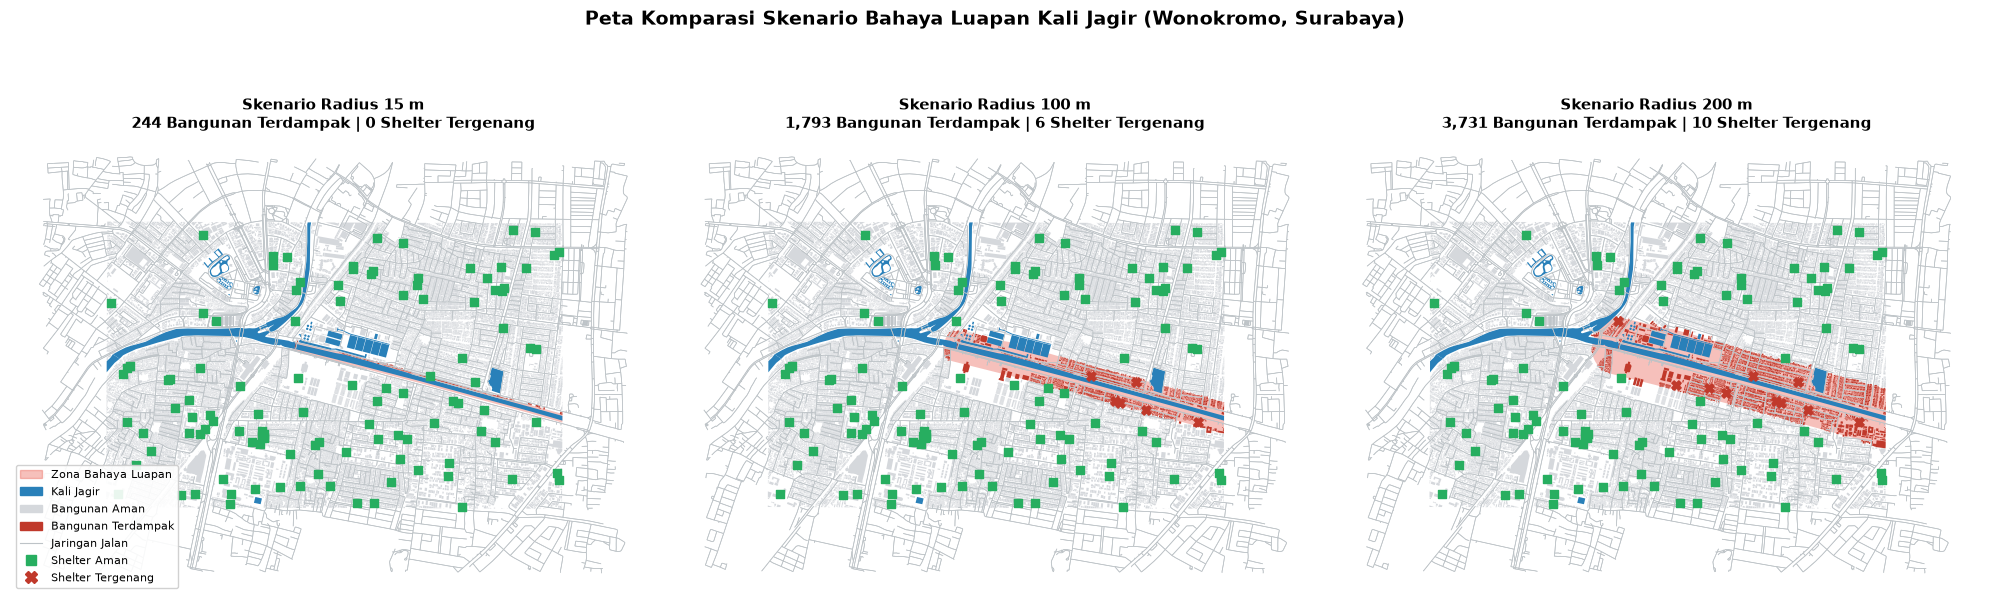

In [6]:
COLORS = {
    "zone": "#e74c3c",
    "water": "#2980b9",
    "building": "#d5d8dc",
    "building_hit": "#c0392b",
    "road": "#bdc3c7",
    "shelter_safe": "#27ae60",
    "shelter_flooded": "#c0392b",
}

LEGEND_HANDLES = [
    Patch(color=COLORS["zone"], alpha=0.35, label="Zona Bahaya Luapan"),
    Patch(color=COLORS["water"], label="Kali Jagir"),
    Patch(color=COLORS["building"], label="Bangunan Aman"),
    Patch(color=COLORS["building_hit"], label="Bangunan Terdampak"),
    Line2D([], [], color=COLORS["road"], linewidth=0.8, label="Jaringan Jalan"),
    Line2D([], [], marker="s", color=COLORS["shelter_safe"], linestyle="", markersize=7, label="Shelter Aman"),
    Line2D([], [], marker="X", color=COLORS["shelter_flooded"], linestyle="", markersize=8, label="Shelter Tergenang"),
]

scenarios_to_plot = [15, 100, 200]
fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))

for ax, r in zip(axes, scenarios_to_plot):
    zone = zones[r]
    hit_mask = dl.spatial_join_affected(buildings, zone)
    flooded_shelter_mask = dl.spatial_join_affected(shelters, zone)
    
    # Render layers
    gpd.GeoSeries([zone], crs=dl.CRS_METER).plot(ax=ax, color=COLORS["zone"], alpha=0.35, zorder=1)
    water.plot(ax=ax, color=COLORS["water"], zorder=2)
    buildings[~hit_mask].plot(ax=ax, color=COLORS["building"], zorder=3)
    if hit_mask.any():
        buildings[hit_mask].plot(ax=ax, color=COLORS["building_hit"], zorder=3)
    roads.plot(ax=ax, color=COLORS["road"], linewidth=0.5, zorder=4)
    shelters[~flooded_shelter_mask].plot(ax=ax, color=COLORS["shelter_safe"], marker="s", markersize=35, zorder=5)
    if flooded_shelter_mask.any():
        shelters[flooded_shelter_mask].plot(ax=ax, color=COLORS["shelter_flooded"], marker="X", markersize=45, zorder=5)
        
    num_hit = int(hit_mask.sum())
    num_flooded = int(flooded_shelter_mask.sum())
    ax.set_title(f"Skenario Radius {r} m\n{num_hit:,} Bangunan Terdampak | {num_flooded} Shelter Tergenang", fontsize=11, fontweight="bold")
    ax.set_axis_off()

axes[0].legend(handles=LEGEND_HANDLES, loc="lower left", fontsize=8, framealpha=0.9)
plt.suptitle("Peta Komparasi Skenario Bahaya Luapan Kali Jagir (Wonokromo, Surabaya)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()

# Simpan luaran ke folder output/
os.makedirs("output", exist_ok=True)
output_map_path = os.path.join("output", "peta_skenario.png")
fig.savefig(output_map_path, dpi=150, bbox_inches="tight")
print(f"Peta skenario berhasil diekspor ke: {output_map_path}")
plt.show()


## 6. Integrasi Modular Proyek (Orang 2 & Orang 3)
Struktur proyek memisahkan fungsionalitas ke dalam modul independen:
- **`src.analysis` (Orang 2):** Matriks translasi homogen 2D (Week 3), uji status warga *Point-in-Polygon* (`within`), pembentukan *subgraph* jalan kering, dan perutean evakuasi terpendek Dijkstra.
- **`src.graphics` (Orang 3):** Dashboard interaktif berbasis `ipywidgets` dan animasi evakuasi kurva Bézier linear diekspor ke GIF (Week 2 & 5).

Di bawah ini adalah demonstrasi integrasi baseline untuk memastikan *pipeline* end-to-end berfungsi penuh.


In [7]:
# Demonstrasi Koordinat Posisi Warga Awal (Simpang Jalan Jagir)
RESIDENT_START_DEG = (112.75026, -7.30208)
resident_pt = gpd.GeoSeries([Point(RESIDENT_START_DEG)], crs=dl.CRS_DEGREE).to_crs(dl.CRS_METER).iloc[0]

print(f"Posisi awal warga (WGS 84)   : {RESIDENT_START_DEG}")
print(f"Posisi awal warga (UTM 49S)  : X={resident_pt.x:.2f} m, Y={resident_pt.y:.2f} m")

# Evaluasi status warga terhadap zona bahaya (Point-in-Polygon)
for r in dl.DEFAULT_SCENARIOS_M:
    zone = zones[r]
    status = "BAHAYA (TERGENANG)" if resident_pt.within(zone) else "AMAN"
    print(f"- Radius {r:3d} m : Status Warga = {status}")


Posisi awal warga (WGS 84)   : (112.75026, -7.30208)
Posisi awal warga (UTM 49S)  : X=693220.30 m, Y=9192481.83 m
- Radius  15 m : Status Warga = AMAN
- Radius 100 m : Status Warga = BAHAYA (TERGENANG)
- Radius 200 m : Status Warga = BAHAYA (TERGENANG)
